# E4 – Alternative chronology-preserving methods (`M3`, `M4`) vs. `M2`

- **Goal:** Test whether keeping time order fixes storage operation and lowers both ROM cost error and Design Regret.
- **Methods compared (`K` ∈ `{48, 96, 192, 384, 768, 1460}`):**
  - **`M2` (Typical hours, `#57`):** 1-hour clusters + hand-picked extreme hours (breaks chronology, keeps peaks).
  - **`M3` (Typical days, 24 h):** Hierarchical clustering of full 24-hour days (`round(K/24)` days, no extreme-day protection; keeps daily chronology).
  - **`M4` (Temporal downsampling):** Averages consecutive hours into `K` equal-length contiguous blocks (keeps full-year order, smooths peaks & daily cycles).
- **Cases:** `pv_bat` (sizing + regret + SOC), `demo` (ROM cost), and `swissx` (input accuracy + clustering speed).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join("..", "scripts")))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import romlab as rl

def try_run(*args):
    try:
        return rl.run(*args)
    except Exception as exc:  # failed runs are reported, not hidden
        return {"error": str(exc).strip().splitlines()[-1]}

print("Variants:", {k: v for k, v in rl.VARIANTS.items()})

Variants: {'M1': 'd436c9b7', 'M1b': 'f69e03d5', 'M2': 'bd1a0c89'}


In [2]:
K_EXP = [48, 96, 192, 384, 768, 1460]
VARS = ["M2", "M3", "M4"]
COLORS = {"M2": "C2", "M3": "C4", "M4": "C3"}
TECHS = ["PV", "Bat", "HP", "Boiler", "TES"]
full_pb = rl.run("pv_bat", "M0", "full")
full_dm = rl.run("demo", "M0", "full")
prof_sx = rl.run("swissx", "M0", "profiles")
rows, sx_rows = [], []
for v in VARS:
    for k in K_EXP:
        r = rl.run("pv_bat", v, "rom", k)
        rg = rl.run("pv_bat", v, "regret", k)
        sc = rl.solution_compare(full_pb, r)
        rd = rl.run("demo", v, "rom", k)
        row = {"variant": v, "target": k, "num_ts": r["num_ts"],
               "obj_err_pct": sc["obj_err"] * 100,
               "regret_pct": (rg["objective"] - full_pb["objective"]) / full_pb["objective"] * 100,
               "cap_diff_pct": sc["cap_abs_diff_rel"] * 100,
               "secs_solve": r["secs_solve"],
               "demo_err_pct": (rd["objective"] - full_dm["objective"]) / full_dm["objective"] * 100}
        for t in TECHS:
            row[t] = r["caps"].get(f"S1,H1,{t}", 0.0)
        rows.append(row)
        rs = rl.run("swissx", v, "cluster", k)
        m = rl.series_metrics(prof_sx, rs); m = m[~m.constant]
        sx_rows.append({"variant": v, "target": k, "num_ts": rs["num_ts"], "secs_cluster": rs["secs_cluster"],
                        "max_err": m["max_err"].abs().mean() * 100,
                        "dc_nrmse": m["dc_nrmse"].mean() * 100,
                        "chr_nrmse": m["chr_nrmse"].mean() * 100})
df = pd.DataFrame(rows); sx = pd.DataFrame(sx_rows)
print("Loaded", len(df), "pv_bat/demo runs and", len(sx), "swissx runs")

Loaded 18 pv_bat/demo runs and 18 swissx runs


## 1. Cost error, Design Regret, sizing error, and solve time (`pv_bat`)

- Compares `M2`, `M3`, and `M4` vs. `M0` across actual clustered steps (log scale).

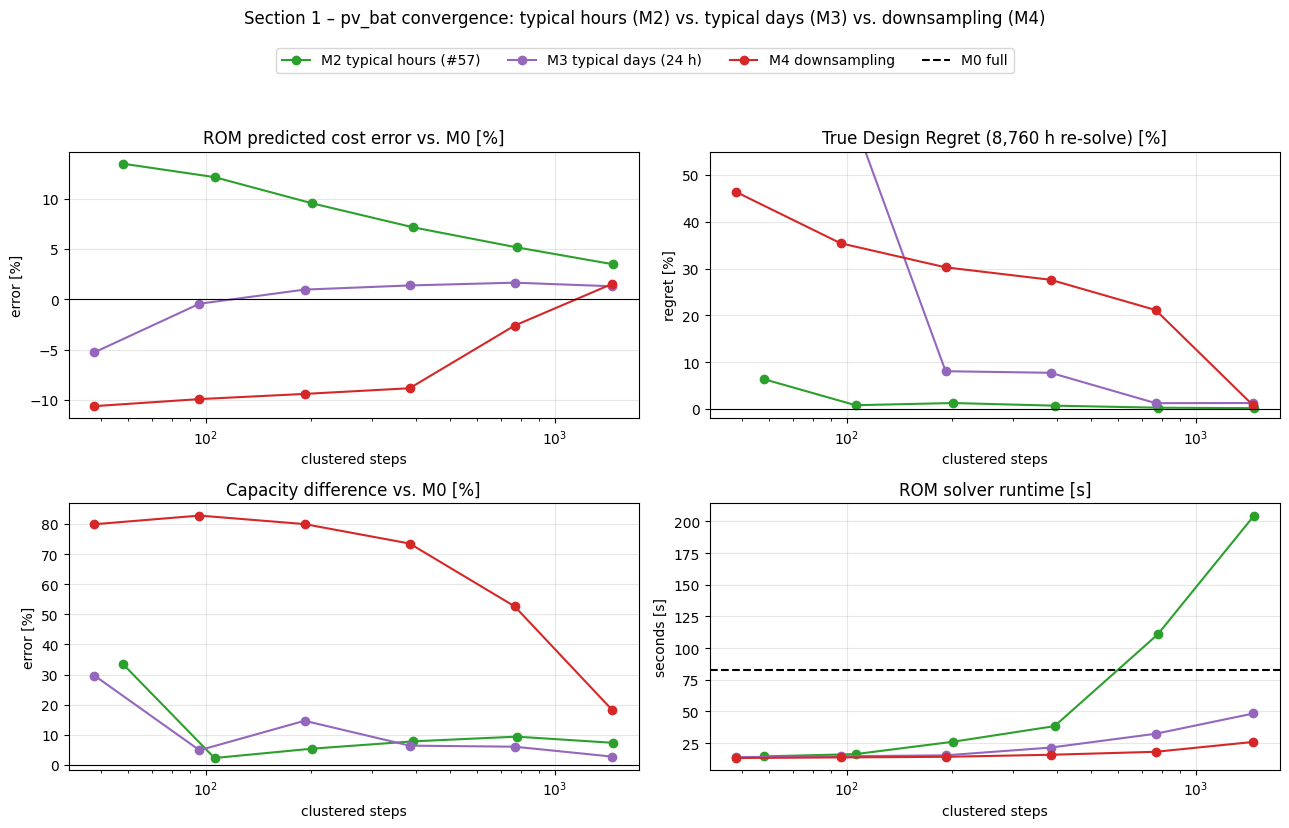

In [3]:
panels = [("obj_err_pct", "ROM predicted cost error vs. M0 [%]", "error [%]"),
          ("regret_pct", "True Design Regret (8,760 h re-solve) [%]", "regret [%]"),
          ("cap_diff_pct", "Capacity difference vs. M0 [%]", "error [%]"),
          ("secs_solve", "ROM solver runtime [s]", "seconds [s]")]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for idx, (col, title, ylab) in enumerate(panels):
    ax = axes[idx // 2, idx % 2]
    for v in VARS:
        d = df[df.variant == v]
        ax.plot(d.num_ts, d[col], marker="o", color=COLORS[v], label=rl.LABELS[v])
    if col == "secs_solve":
        ax.axhline(full_pb["secs_solve"], color="k", ls="--", label="M0 full")
    else:
        ax.axhline(0, color="k", lw=0.8)
    if col == "regret_pct":
        ax.set_ylim(-2, 55)
    ax.set_xscale("log"); ax.set_title(title); ax.set_xlabel("clustered steps"); ax.set_ylabel(ylab); ax.grid(True, alpha=0.3)
handles, labels = axes[1, 1].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.99))
fig.suptitle("Section 1 – pv_bat convergence: typical hours (M2) vs. typical days (M3) vs. downsampling (M4)", y=1.03)
plt.tight_layout(rect=[0, 0, 1, 0.94])

**Summary (Section 1):**
- **ROM cost error:** `M3` slashes operating-cost error to **`+0.96 %`** at `K=192` (`8` days) vs. `+9.52 %` for `M2`; `M4` severely under-predicts cost (`-9.4 %` to `-10.6 %` at `K ≤ 384`).
- **Design Regret (plot clipped at `55 %`):** **`M2` wins (`0.79–1.25 %` at `K=96–192`)**. Plain `M3` misses cold-snap peaks (`+227 %` at `K=48`, `+70 %` at `K=96`, `+8.1 %` at `K=192`); `M4` drops storage (`+21–46 %` regret at `K ≤ 768`).
- **Solve time:** `M3` and `M4` solve `2–3×` faster than `M0` (`13–22 s` up to `K=384` vs. `40 s` for `M0`).

## 2. Installed technology mix & `Bat` SOC trajectory (`K ≈ 192`)

- **Left:** Chosen capacities relative to `M0` (`1.0` = exact) at `K=192`.
- **Right:** Winter-week `Bat` SOC (`days 20–27`) showing why `M3` matches `M0` operation while `M4` drops battery storage.

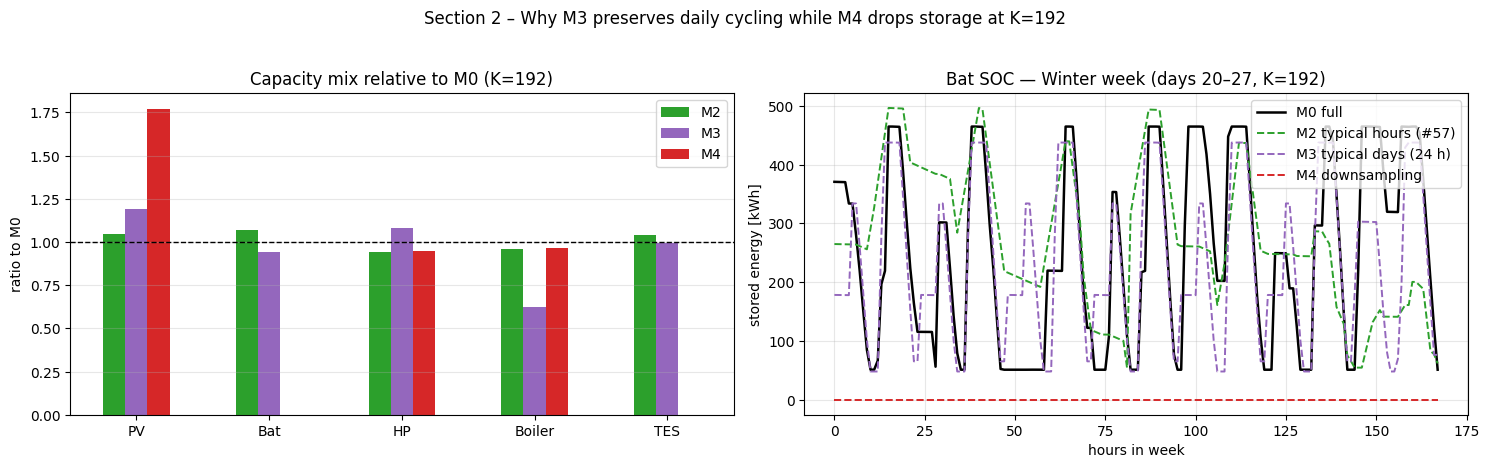

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
k192 = df[df.target == 192].set_index("variant")
m0_caps = {t: full_pb["caps"].get(f"S1,H1,{t}", 0.0) for t in TECHS}
ratios = pd.DataFrame({v: [k192.loc[v, t] / m0_caps[t] for t in TECHS] for v in VARS}, index=TECHS)
ratios.plot.bar(ax=axes[0], rot=0, color=[COLORS[v] for v in VARS])
axes[0].axhline(1.0, color="k", ls="--", lw=1, label="M0 full")
axes[0].set_title("Capacity mix relative to M0 (K=192)"); axes[0].set_ylabel("ratio to M0"); axes[0].grid(axis="y", alpha=0.3)
a, b = 20 * 24, 27 * 24
hrs = np.arange(a, b) - a
axes[1].plot(hrs, full_pb["soc"]["S1,H1,Bat"][a:b], color="k", lw=1.8, label="M0 full")
for v in VARS:
    r = rl.run("pv_bat", v, "rom", 192)
    axes[1].plot(hrs, r["soc"]["S1,H1,Bat"][a:b], color=COLORS[v], ls="--", lw=1.4, label=rl.LABELS[v])
axes[1].set_title("Bat SOC — Winter week (days 20–27, K=192)"); axes[1].set_xlabel("hours in week"); axes[1].set_ylabel("stored energy [kWh]")
axes[1].grid(True, alpha=0.3); axes[1].legend()
fig.suptitle("Section 2 – Why M3 preserves daily cycling while M4 drops storage at K=192", y=1.03)
plt.tight_layout()

**Summary (Section 2):**
- At `K=192`, `M4` averages over `45.6`-hour blocks, erasing diurnal arbitrage so it builds **`0 kWh` `Bat` and `0 kWh` `TES`** (and compensates by over-building `PV` `1.77×`).
- `M3` preserves daily `Bat` cycling (`SOC` tracks `M0` closely), but without extreme-day protection it under-sizes `Boiler` (`36.8` vs. `58.9 kW`).

## 3. Cross-check on `demo` cost error and `swissx` clustering metrics

- **Panels:** `demo` cost error, `swissx` mean peak error (`max_err`), `swissx` hourly match error (`chr_nrmse`), and `swissx` clustering time (`secs_cluster`).

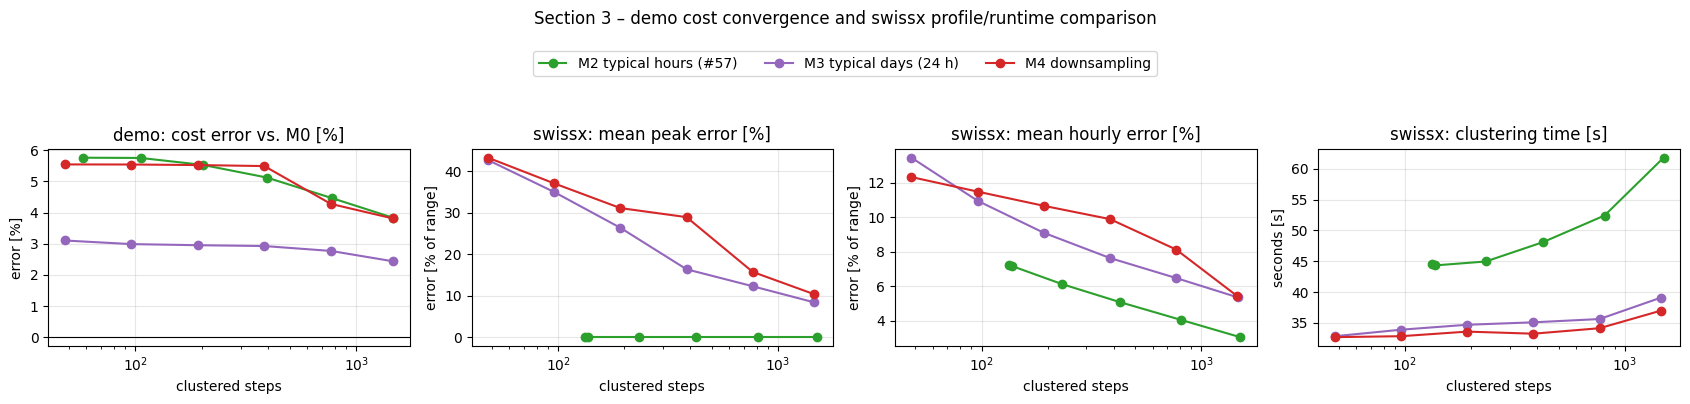

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for v in VARS:
    d = df[df.variant == v]; ds = sx[sx.variant == v]
    axes[0].plot(d.num_ts, d.demo_err_pct, marker="o", color=COLORS[v], label=rl.LABELS[v])
    axes[1].plot(ds.num_ts, ds.max_err, marker="o", color=COLORS[v], label=rl.LABELS[v])
    axes[2].plot(ds.num_ts, ds.chr_nrmse, marker="o", color=COLORS[v], label=rl.LABELS[v])
    axes[3].plot(ds.num_ts, ds.secs_cluster, marker="o", color=COLORS[v], label=rl.LABELS[v])
axes[0].axhline(0, color="k", lw=0.8); axes[0].set_title("demo: cost error vs. M0 [%]"); axes[0].set_ylabel("error [%]")
axes[1].set_title("swissx: mean peak error [%]"); axes[1].set_ylabel("error [% of range]")
axes[2].set_title("swissx: mean hourly error [%]"); axes[2].set_ylabel("error [% of range]")
axes[3].set_title("swissx: clustering time [s]"); axes[3].set_ylabel("seconds [s]")
for ax in axes:
    ax.set_xscale("log"); ax.set_xlabel("clustered steps"); ax.grid(True, alpha=0.3)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.96))
fig.suptitle("Section 3 – demo cost convergence and swissx profile/runtime comparison", y=1.05)
plt.tight_layout(rect=[0, 0, 1, 0.87])

**Summary (Section 3):**
- On `demo`, `M3` halves cost error vs. `M2` (`+2.95 %` vs. `+5.53 %` at `K=192`); `M4` barely improves on `M2` (`+5.53 %` at `K=192`).
- On `swissx`, only `M2` preserves peaks (`0.0 %` error vs. `26.3 %` in `M3` and `31.1 %` in `M4` at `K=192`), and `M2` also has the lowest `chr_nrmse` (`6.1 %` vs. `9.1 %` / `10.7 %`), while `M3`/`M4` cluster slightly faster (`34–36 s` vs. `45–52 s`).

## Findings (E4)

- **Key takeaway:**
  - Neither plain `M3` nor `M4` is a drop-in replacement for `M2` — each solves one piece and breaks another.
- **Comparison by method:**
  - **`M2` (Typical hours + extremes):** Highest ROM operating-cost error (`+9.5 %` on `pv_bat` at `K=192`), **yet lowest Design Regret (`0.79–1.25 %` at `K=96–192`)** and `0 %` peak error on `swissx`.
  - **`M3` (Typical days, no extremes):** Slashes ROM operating-cost error (`+0.96 %` on `pv_bat` and `+2.95 %` on `demo` at `K=192`) by keeping 24 h storage cycles intact, **but missing extreme days causes `0 kW` Boiler at `K ≤ 96` (`+70–227 %` regret) and `+8.1 %` regret at `K=192`**.
  - **`M4` (Downsampling):** Fails whenever block length approaches or exceeds the diurnal cycle (`K ≤ 768`), wiping out `Bat` and `TES` investments (`+21–46 %` regret).
- **Recommendation:**
  - Keep **`M2`** as the immediate fix for `#57` (best sizing and lowest regret out of the box).
  - If high operating-cost accuracy with storage is needed in a future feature, build **`M3 + extreme-day protection`** (combining `M3`'s 24 h chronology with `M2`'s extreme protection).